In [36]:
file_path = r"D:\Python Project\CrediScope\data\accepted_2007_to_2018Q4.csv"

In [37]:

import pandas as pd
import numpy as np

features = [
    "loan_amnt",
    "annual_inc",
    "int_rate",
    "installment",
    "dti",
    "delinq_2yrs",
    "inq_last_6mths",
    "open_acc",
    "revol_bal",
    "revol_util",
    "total_acc",
    "pub_rec"
]

status_mapping = {
    "Fully Paid": 0,
    "Charged Off": 1,
    "Default": 1
}

sample_chunks = []

for chunk in pd.read_csv(
    file_path,
    usecols=features + ["loan_status"],
    chunksize=100_000,
    low_memory=False
):
    chunk = chunk[chunk["loan_status"].isin(status_mapping)]

    chunk["loan_status"] = chunk["loan_status"].map(status_mapping)

    sample_chunks.append(chunk.sample(frac=0.1, random_state=42))

    if sum(len(x) for x in sample_chunks) >= 100_000:
        break

eda_sample = pd.concat(sample_chunks, ignore_index=True)

print("Sample records:", len(eda_sample))
display(eda_sample.describe().T)


Sample records: 105363


,count,mean,std,min,25%,50%,75%,max
loan_amnt,105363.0,14480.936145,8718.789245,725.00,8000.000,12000.00,20000.00,40000.00
int_rate,105363.0,13.018900,4.728451,5.31,9.430,12.62,15.61,30.99
installment,105363.0,437.684255,260.767925,4.93,248.455,374.33,579.17,1715.42
annual_inc,105363.0,76469.432653,73196.480283,0.00,46000.000,65000.00,90800.00,9000000.00
loan_status,105363.0,0.201371,0.401026,0.00,0.000,0.00,0.00,1.00
dti,105329.0,18.402933,9.407538,0.00,11.890,17.76,24.20,697.04
delinq_2yrs,105363.0,0.325361,0.884212,0.00,0.000,0.00,0.00,21.00
inq_last_6mths,105363.0,0.643053,0.929331,0.00,0.000,0.00,1.00,8.00
open_acc,105363.0,11.667397,5.528331,0.00,8.000,11.00,14.00,63.00
pub_rec,105363.0,0.223883,0.626810,0.00,0.000,0.00,0.00,63.00


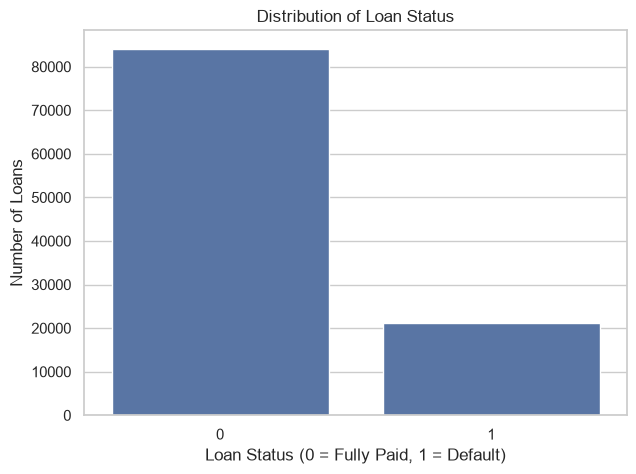

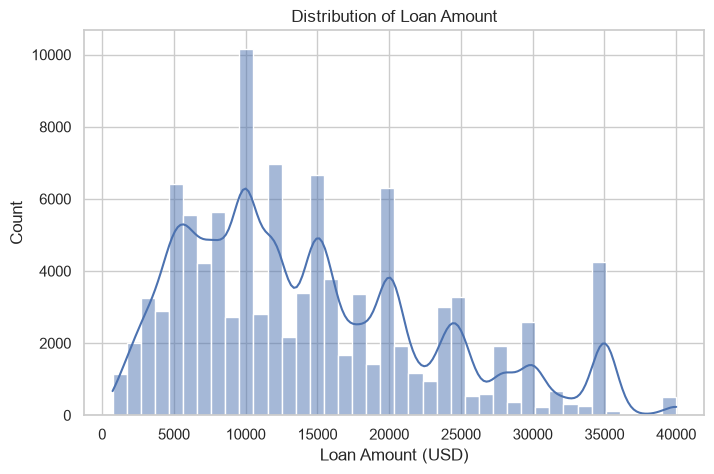

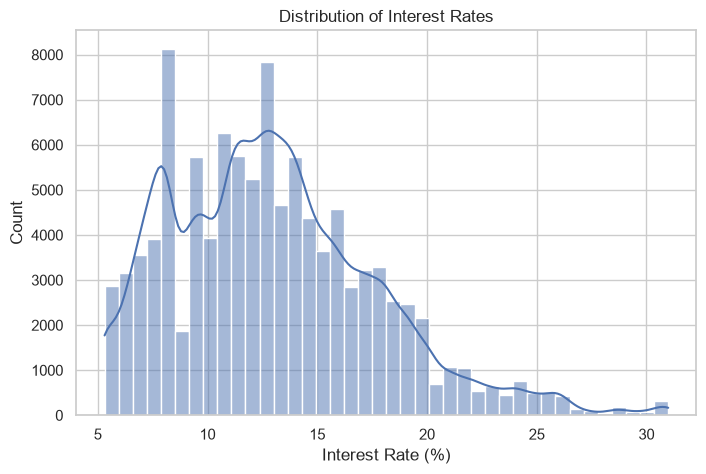

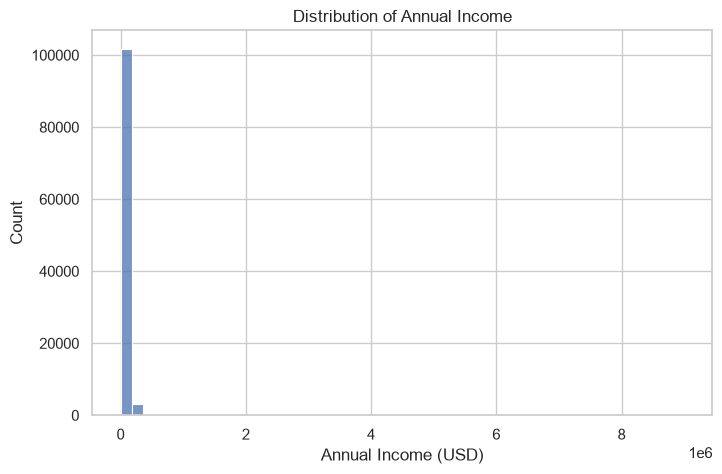

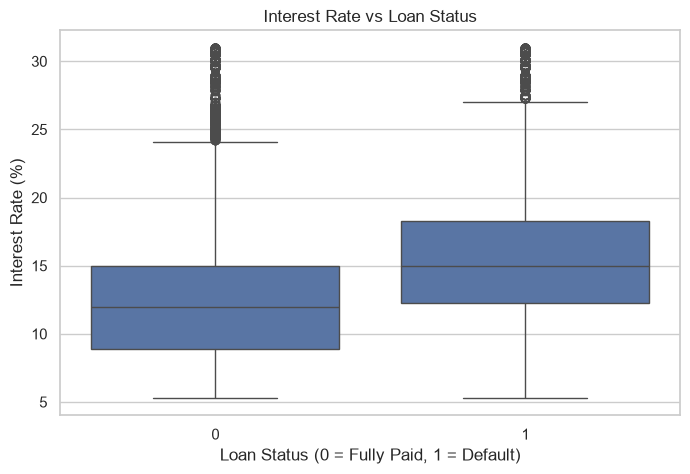

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Loan status distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=eda_sample, x="loan_status")
plt.title("Distribution of Loan Status")
plt.xlabel("Loan Status (0 = Fully Paid, 1 = Default)")
plt.ylabel("Number of Loans")
plt.show()

# 2. Loan amount distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=eda_sample, x="loan_amnt", bins=40, kde=True)
plt.title("Distribution of Loan Amount")
plt.xlabel("Loan Amount (USD)")
plt.show()

# 3. Interest rate distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=eda_sample, x="int_rate", bins=40, kde=True)
plt.title("Distribution of Interest Rates")
plt.xlabel("Interest Rate (%)")
plt.show()

# 4. Annual income distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=eda_sample, x="annual_inc", bins=50)
plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income (USD)")
plt.show()

# 5. Default rate by loan status
plt.figure(figsize=(8, 5))
sns.boxplot(data=eda_sample, x="loan_status", y="int_rate")
plt.title("Interest Rate vs Loan Status")
plt.xlabel("Loan Status (0 = Fully Paid, 1 = Default)")
plt.ylabel("Interest Rate (%)")
plt.show()

In [39]:
categorical_features = [
    "grade",
    "emp_length",
    "home_ownership",
    "purpose",
    "term",
    "verification_status"
]

categorical_chunks = []

status_mapping = {
    "Fully Paid": 0,
    "Charged Off": 1,
    "Default": 1
}

chunk_number = 0

for chunk in pd.read_csv(
    file_path,
    usecols=categorical_features + ["loan_status"],
    chunksize=100_000,
    low_memory=False
):
    chunk = chunk[chunk["loan_status"].isin(status_mapping)].copy()

    chunk["loan_status"] = chunk["loan_status"].map(status_mapping)

    categorical_chunks.append(
        chunk.sample(frac=0.05, random_state=42 + chunk_number)
    )

    chunk_number += 1

categorical_sample = pd.concat(
    categorical_chunks,
    ignore_index=True
)

print("Categorical sample records:", len(categorical_sample))

Categorical sample records: 67268


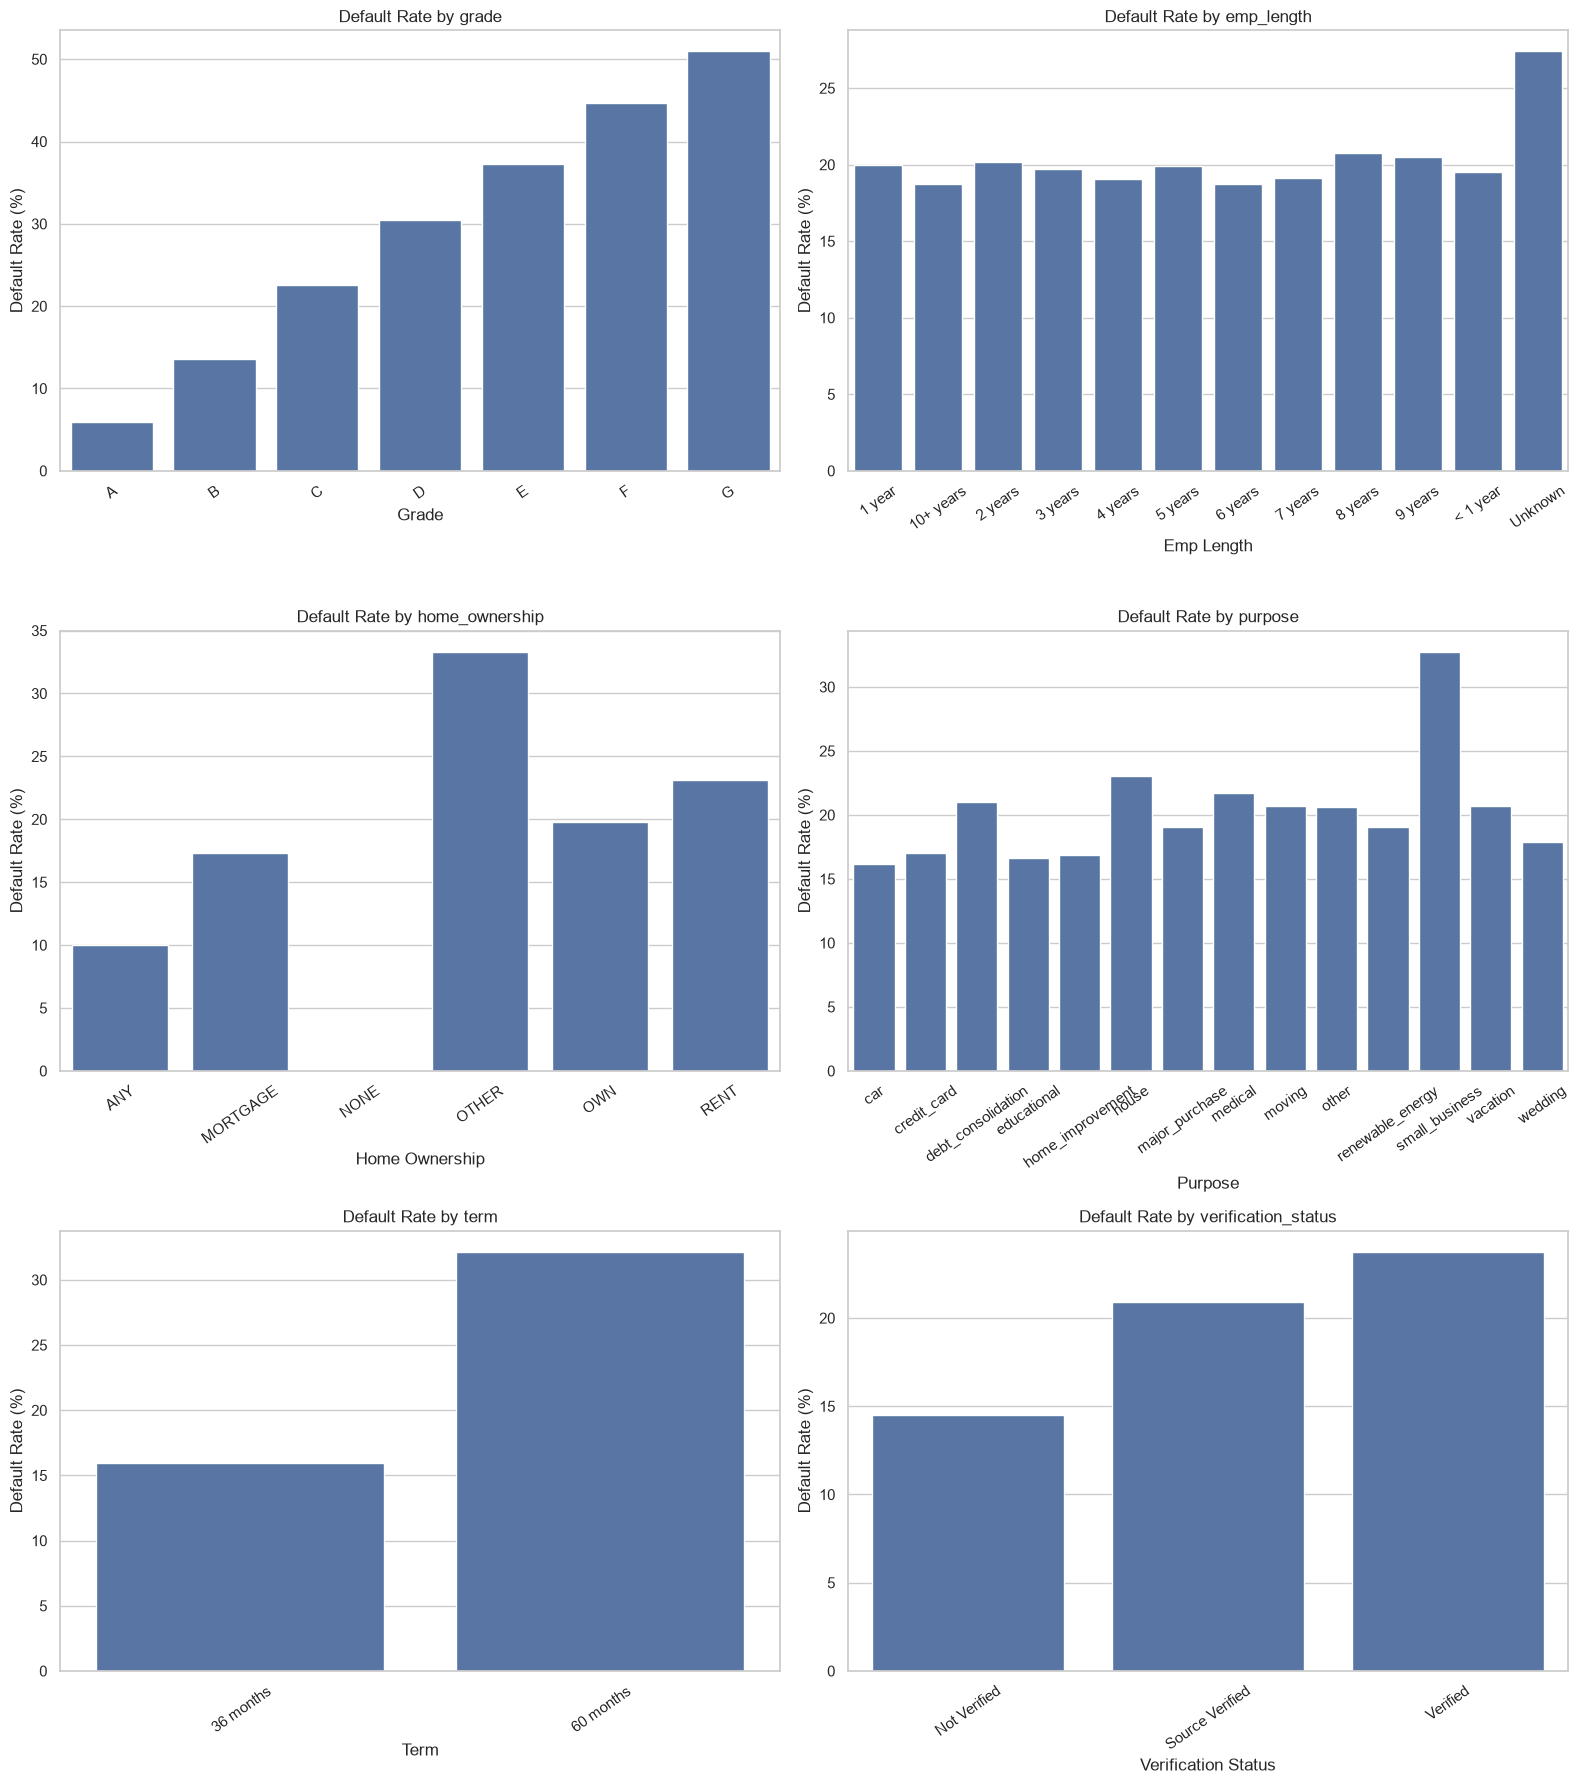

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

categorical_features = [
    "grade",
    "emp_length",
    "home_ownership",
    "purpose",
    "term",
    "verification_status"
]

# Replace missing categorical values
categorical_sample[categorical_features] = (
    categorical_sample[categorical_features].fillna("Unknown")
)

fig, axes = plt.subplots(3, 2, figsize=(16, 18))

for feature, ax in zip(categorical_features, axes.flatten()):

    summary = (
        categorical_sample
        .groupby(feature, observed=True)["loan_status"]
        .agg(["mean", "count"])
        .reset_index()
    )

    summary["default_rate"] = summary["mean"] * 100

    # Sort loan grades in their natural order
    if feature == "grade":
        summary[feature] = pd.Categorical(
            summary[feature],
            categories=["A", "B", "C", "D", "E", "F", "G"],
            ordered=True
        )
        summary = summary.sort_values(feature)

    sns.barplot(
        data=summary,
        x=feature,
        y="default_rate",
        ax=ax
    )

    ax.set_title(f"Default Rate by {feature}")
    ax.set_xlabel(feature.replace("_", " ").title())
    ax.set_ylabel("Default Rate (%)")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

In [41]:
for feature in categorical_features:

    summary = (
        categorical_sample
        .groupby(feature, dropna=False)["loan_status"]
        .agg(
            total_loans="count",
            defaults="sum",
            default_rate="mean"
        )
        .reset_index()
    )

    summary["default_rate"] = (
        summary["default_rate"] * 100
    ).round(2)

    print(f"\n{'=' * 60}")
    print(f"Default statistics by {feature}")
    print("=" * 60)

    display(summary.sort_values("default_rate", ascending=False))


Default statistics by grade


,grade,total_loans,defaults,default_rate
6,G,477,243,50.94
5,F,1546,691,44.70
4,E,4727,1762,37.28
3,D,9797,2984,30.46
2,C,19096,4300,22.52
1,B,19758,2686,13.59
0,A,11867,707,5.96



Default statistics by emp_length


,emp_length,total_loans,defaults,default_rate
11,Unknown,3964,1086,27.40
8,8 years,3003,624,20.78
9,9 years,2566,526,20.50
2,2 years,6164,1244,20.18
0,1 year,4411,881,19.97
5,5 years,4248,845,19.89
3,3 years,5424,1071,19.75
10,< 1 year,5468,1067,19.51
7,7 years,2908,557,19.15
4,4 years,4010,764,19.05



Default statistics by home_ownership


,home_ownership,total_loans,defaults,default_rate
3,OTHER,9,3,33.33
5,RENT,26644,6157,23.11
4,OWN,7223,1429,19.78
1,MORTGAGE,33369,5782,17.33
0,ANY,20,2,10.00
2,NONE,3,0,0.00


... (2 outputs left out)


Default statistics by term


,term,total_loans,defaults,default_rate
1,60 months,16302,5244,32.17
0,36 months,50966,8129,15.95



Default statistics by verification_status


,verification_status,total_loans,defaults,default_rate
2,Verified,21059,5004,23.76
1,Source Verified,25938,5428,20.93
0,Not Verified,20271,2941,14.51


In [42]:
import pandas as pd

status_mapping = {
    "Fully Paid": 0,
    "Charged Off": 1,
    "Default": 1
}

monthly_stats = []

for chunk in pd.read_csv(
    file_path,
    usecols=["issue_d", "loan_status"],
    chunksize=100_000,
    low_memory=False
):
    chunk = chunk[chunk["loan_status"].isin(status_mapping)].copy()

    chunk["loan_status"] = chunk["loan_status"].map(status_mapping)

    chunk["issue_date"] = pd.to_datetime(
        chunk["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )

    chunk = chunk.dropna(subset=["issue_date"])

    chunk["issue_month"] = chunk["issue_date"].dt.to_period("M")

    monthly_stats.append(
        chunk.groupby("issue_month")["loan_status"]
        .agg(total_loans="count", defaults="sum")
    )

monthly_summary = (
    pd.concat(monthly_stats)
    .groupby(level=0)
    .sum()
)

monthly_summary["default_rate"] = (
    monthly_summary["defaults"] /
    monthly_summary["total_loans"] * 100
)

display(monthly_summary.head(12))
display(monthly_summary.tail(24))

print("Earliest issue month:", monthly_summary.index.min())
print("Latest issue month:", monthly_summary.index.max())

,total_loans,defaults,default_rate
issue_month,,,
2007-06,1,0,0.000000
2007-07,30,0,0.000000
2007-08,33,7,21.212121
2007-09,18,3,16.666667
2007-10,47,10,21.276596
2007-11,37,7,18.918919
2007-12,85,18,21.176471
2008-01,171,31,18.128655
2008-02,174,25,14.367816


,total_loans,defaults,default_rate
issue_month,,,
2017-01,16395,3720,22.689844
2017-02,13468,3127,23.217998
2017-03,17011,3904,22.949856
2017-04,13104,3119,23.801893
2017-05,16153,3868,23.946016
2017-06,15235,3604,23.656055
2017-07,14959,3601,24.072465
2017-08,15489,3547,22.900123
2017-09,13406,3350,24.988811


Earliest issue month: 2007-06
Latest issue month: 2018-12


In [43]:
yearly_summary = monthly_summary.copy()

yearly_summary["year"] = (
    yearly_summary.index.year
)

yearly_summary = (
    yearly_summary
    .groupby("year")
    [["total_loans", "defaults"]]
    .sum()
)

yearly_summary["default_rate"] = (
    yearly_summary["defaults"] /
    yearly_summary["total_loans"] * 100
)

yearly_summary["default_rate"] = (
    yearly_summary["default_rate"].round(2)
)

display(yearly_summary)


,total_loans,defaults,default_rate
year,,,
2007,251,45,17.93
2008,1562,247,15.81
2009,4716,594,12.60
2010,11536,1487,12.89
2011,21721,3297,15.18
2012,53367,8644,16.20
2013,134804,21024,15.60
2014,223103,41162,18.45
2015,375546,75804,20.19


In [44]:
# Restrict the population to the proposed maturity cutoff
eligible_monthly = monthly_summary.loc[
    :"2013-12"
].copy()

total_loans = eligible_monthly["total_loans"].sum()

# Cumulative loan counts
eligible_monthly["cumulative_loans"] = (
    eligible_monthly["total_loans"].cumsum()
)

# Find chronological boundaries
train_cutoff = eligible_monthly[
    eligible_monthly["cumulative_loans"] >= total_loans * 0.70
].index[0]

validation_cutoff = eligible_monthly[
    eligible_monthly["cumulative_loans"] >= total_loans * 0.85
].index[0]

print("Total eligible loans:", total_loans)
print("Training ends:", train_cutoff)
print("Validation ends:", validation_cutoff)
print("Testing ends:", eligible_monthly.index.max())

# Calculate approximate split sizes
train = eligible_monthly.loc[:train_cutoff]
validation = eligible_monthly.loc[
    (eligible_monthly.index > train_cutoff) &
    (eligible_monthly.index <= validation_cutoff)
]
test = eligible_monthly.loc[validation_cutoff < eligible_monthly.index]

print("\nTraining loans:", train["total_loans"].sum())
print("Validation loans:", validation["total_loans"].sum())
print("Testing loans:", test["total_loans"].sum())

Total eligible loans: 227957
Training ends: 2013-08
Validation ends: 2013-10
Testing ends: 2013-12

Training loans: 171111
Validation loans: 27114
Testing loans: 29732


In [45]:
splits = {
    "Training": train,
    "Validation": validation,
    "Testing": test
}

for name, data in splits.items():

    total = data["total_loans"].sum()
    defaults = data["defaults"].sum()
    paid = total - defaults
    rate = defaults / total * 100

    print(f"\n{name}")
    print("-" * 35)
    print("Total loans:", total)
    print("Fully paid:", paid)
    print("Defaults:", defaults)
    print(f"Default rate: {rate:.2f}%")


Training
-----------------------------------
Total loans: 171111
Fully paid: 144607
Defaults: 26504
Default rate: 15.49%

Validation
-----------------------------------
Total loans: 27114
Fully paid: 22845
Defaults: 4269
Default rate: 15.74%

Testing
-----------------------------------
Total loans: 29732
Fully paid: 25167
Defaults: 4565
Default rate: 15.35%


In [46]:

import pandas as pd
from collections import defaultdict

file_path = r"D:\Python Project\CrediScope\data\accepted_2007_to_2018Q4.csv"

yearly_counts = defaultdict(lambda: {
    "total": 0,
    "fully_paid": 0,
    "defaults": 0
})

for chunk in pd.read_csv(
    file_path,
    usecols=["issue_d", "loan_status"],
    chunksize=100_000,
    low_memory=False
):
    eligible = chunk["loan_status"].isin([
        "Fully Paid",
        "Charged Off",
        "Default"
    ])

    data = chunk.loc[eligible, ["issue_d", "loan_status"]].copy()

    data["issue_d"] = pd.to_datetime(
        data["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )

    data = data.dropna(subset=["issue_d"])
    data["year"] = data["issue_d"].dt.year

    data = data[data["year"].between(2007, 2013)]

    for year, group in data.groupby("year"):
        year = int(year)

        yearly_counts[year]["total"] += len(group)
        yearly_counts[year]["fully_paid"] += (
            group["loan_status"] == "Fully Paid"
        ).sum()
        yearly_counts[year]["defaults"] += (
            group["loan_status"].isin(["Charged Off", "Default"])
        ).sum()

results = []

for year in sorted(yearly_counts):
    counts = yearly_counts[year]

    results.append({
        "Year": year,
        "Total Loans": counts["total"],
        "Fully Paid": counts["fully_paid"],
        "Defaults": counts["defaults"],
        "Default Rate (%)": round(
            counts["defaults"] / counts["total"] * 100, 2
        )
    })

yearly_df = pd.DataFrame(results)
display(yearly_df)


,Year,Total Loans,Fully Paid,Defaults,Default Rate (%)
0,2007,251,206,45,17.93
1,2008,1562,1315,247,15.81
2,2009,4716,4122,594,12.60
3,2010,11536,10049,1487,12.89
4,2011,21721,18424,3297,15.18
5,2012,53367,44723,8644,16.20
6,2013,134804,113780,21024,15.60


In [47]:

train_years = [2007, 2008, 2009, 2010, 2011]
validation_years = [2012]
test_years = [2013]

split_definitions = {
    "Training": train_years,
    "Validation": validation_years,
    "Testing": test_years
}

split_results = []

for split_name, years in split_definitions.items():
    subset = yearly_df[yearly_df["Year"].isin(years)]

    total = subset["Total Loans"].sum()
    defaults = subset["Defaults"].sum()
    fully_paid = subset["Fully Paid"].sum()

    split_results.append({
        "Split": split_name,
        "Years": f"{min(years)}–{max(years)}",
        "Total Loans": total,
        "Fully Paid": fully_paid,
        "Defaults": defaults,
        "Default Rate (%)": round(defaults / total * 100, 2),
        "Dataset Share (%)": round(
            total / yearly_df["Total Loans"].sum() * 100, 2
        )
    })

split_df = pd.DataFrame(split_results)
display(split_df)


,Split,Years,Total Loans,Fully Paid,Defaults,Default Rate (%),Dataset Share (%)
0,Training,2007–2011,39786,34116,5670,14.25,17.45
1,Validation,2012–2012,53367,44723,8644,16.20,23.41
2,Testing,2013–2013,134804,113780,21024,15.60,59.14


In [48]:

# Prepare the full chronological modelling dataset

model_features = [
    "loan_amnt", "term", "int_rate", "installment", "grade",
    "emp_length", "home_ownership", "annual_inc",
    "verification_status", "purpose", "dti", "delinq_2yrs",
    "inq_last_6mths", "open_acc", "revol_bal", "revol_util",
    "total_acc", "pub_rec"
]

status_mapping = {
    "Fully Paid": 0,
    "Charged Off": 1,
    "Default": 1
}

model_chunks = []

for chunk_number, chunk in enumerate(pd.read_csv(
    file_path,
    usecols=model_features + ["issue_d", "loan_status"],
    chunksize=100_000,
    low_memory=False
), start=1):

    # Keep loans with completed outcomes
    chunk = chunk[
        chunk["loan_status"].isin(status_mapping)
    ].copy()

    # Parse issue date
    chunk["issue_d"] = pd.to_datetime(
        chunk["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )

    chunk = chunk.dropna(subset=["issue_d"]).copy()
    chunk["issue_year"] = chunk["issue_d"].dt.year

    # Keep only 2007–2013
    chunk = chunk[
        chunk["issue_year"].between(2007, 2013)
    ].copy()

    # Create binary target
    chunk["target"] = chunk["loan_status"].map(status_mapping)

    # Assign chronological split
    chunk["split"] = np.select(
        [
            chunk["issue_year"].between(2007, 2011),
            chunk["issue_year"].eq(2012),
            chunk["issue_year"].eq(2013)
        ],
        ["Training", "Validation", "Testing"],
        default="Exclude"
    )

    model_chunks.append(chunk)

    print(f"Processed chunk {chunk_number}")

# Combine all eligible records
model_data = pd.concat(model_chunks, ignore_index=True)

# Sort by issue date
model_data = model_data.sort_values(
    "issue_d"
).reset_index(drop=True)

# Save prepared dataset
output_path = r"D:\Python Project\CrediScope\data\crediscope_model_data.csv"
model_data.to_csv(output_path, index=False)

print("\nDataset preparation completed.")
print("Total records:", len(model_data))
print("Total defaults:", int(model_data["target"].sum()))
print("Saved to:", output_path)


Processed chunk 1
Processed chunk 2
Processed chunk 3
Processed chunk 4
Processed chunk 5
Processed chunk 6
Processed chunk 7
Processed chunk 8
Processed chunk 9
Processed chunk 10
Processed chunk 11
Processed chunk 12
Processed chunk 13
Processed chunk 14
Processed chunk 15
Processed chunk 16
Processed chunk 17
Processed chunk 18
Processed chunk 19
Processed chunk 20
Processed chunk 21
Processed chunk 22
Processed chunk 23

Dataset preparation completed.
Total records: 227957
Total defaults: 35338
Saved to: D:\Python Project\CrediScope\data\crediscope_model_data.csv


In [49]:

# Verify split sizes and class distribution

split_summary = (
    model_data.groupby("split")
    .agg(
        total_loans=("target", "size"),
        fully_paid=("target", lambda x: (x == 0).sum()),
        defaults=("target", "sum"),
        default_rate_pct=("target", lambda x: x.mean() * 100)
    )
)

split_summary["dataset_share_pct"] = (
    split_summary["total_loans"] / len(model_data) * 100
)

split_summary = split_summary.round(2)

print(split_summary)

print("\nYear range in each split:")
print(model_data.groupby("split")["issue_year"].agg(["min", "max"]))

print("\nTotal records:", len(model_data))
print("Total defaults:", int(model_data["target"].sum()))
print("Overall default rate:", round(model_data["target"].mean() * 100, 2), "%")


            total_loans  fully_paid defaults  default_rate_pct  \
split                                                            
Testing          134804      113780    21024             15.60   
Training          39786       34116     5670             14.25   
Validation        53367       44723     8644             16.20   

            dataset_share_pct  
split                          
Testing                 59.14  
Training                17.45  
Validation              23.41  

Year range in each split:
             min   max
split                 
Testing     2013  2013
Training    2007  2011
Validation  2012  2012

Total records: 227957
Total defaults: 35338
Overall default rate: 15.5 %


In [50]:

# Data quality checks

print("Dataset shape:", model_data.shape)

print("\nData types:")
print(model_data.dtypes)

print("\nMissing values:")
missing_summary = pd.DataFrame({
    "Missing Count": model_data.isnull().sum(),
    "Missing Percentage": (
        model_data.isnull().mean() * 100
    ).round(2)
})

print(missing_summary[missing_summary["Missing Count"] > 0])

print("\nDuplicate rows:", model_data.duplicated().sum())

print("\nTarget distribution:")
print(model_data["target"].value_counts())

print("\nSplit distribution:")
print(model_data["split"].value_counts())


Dataset shape: (227957, 23)

Data types:
loan_amnt                     float64
term                              str
int_rate                      float64
installment                   float64
grade                             str
emp_length                        str
home_ownership                    str
annual_inc                    float64
verification_status               str
issue_d                datetime64[us]
loan_status                       str
purpose                           str
dti                           float64
delinq_2yrs                   float64
inq_last_6mths                float64
open_acc                      float64
pub_rec                       float64
revol_bal                     float64
revol_util                    float64
total_acc                     float64
issue_year                      int32
target                         object
split                             str
dtype: object

Missing values:
            Missing Count  Missing Percentage
emp_leng

In [51]:
# Ensure target is stored as an integer
model_data["target"] = model_data["target"].astype("int8")

print("Target data type:", model_data["target"].dtype)
print("\nTarget values:")
print(model_data["target"].value_counts().sort_index())

Target data type: int8

Target values:
target
0    192619
1     35338
Name: count, dtype: int64


In [52]:
print("DATA QUALITY REPORT")
print("=" * 40)

print("\n1. Dataset shape:", model_data.shape)

print("\n2. Missing values:")
missing = model_data.isnull().sum()
print(missing[missing > 0] if missing.any() else "No missing values")

print("\n3. Target distribution:")
print(model_data["target"].value_counts().sort_index())

print("\n4. Duplicate rows:")
print(model_data.duplicated().sum())

print("\n5. Split counts:")
print(model_data["split"].value_counts())

print("\n6. Year boundaries:")
print(model_data.groupby("split")["issue_year"].agg(["min", "max"]))

DATA QUALITY REPORT

1. Dataset shape: (227957, 23)

2. Missing values:
emp_length    8965
revol_util     175
dtype: int64

3. Target distribution:
target
0    192619
1     35338
Name: count, dtype: int64

4. Duplicate rows:
0

5. Split counts:
split
Testing       134804
Validation     53367
Training       39786
Name: count, dtype: int64

6. Year boundaries:
             min   max
split                 
Testing     2013  2013
Training    2007  2011
Validation  2012  2012


In [53]:
model_data.to_csv(output_path, index=False)
print("Updated modelling dataset saved successfully.")

Updated modelling dataset saved successfully.


In [55]:

# Define model input features
X_train = model_data.loc[
    model_data["split"] == "Training", model_features
]

X_val = model_data.loc[
    model_data["split"] == "Validation", model_features
]

X_test = model_data.loc[
    model_data["split"] == "Testing", model_features
]

# Define target variables
y_train = model_data.loc[
    model_data["split"] == "Training", "target"
]

y_val = model_data.loc[
    model_data["split"] == "Validation", "target"
]

y_test = model_data.loc[
    model_data["split"] == "Testing", "target"
]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (39786, 18) (39786,)
Validation: (53367, 18) (53367,)
Testing: (134804, 18) (134804,)


### Data Preprocessing Pipeline

In [56]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate numerical and categorical features
numerical_features = [
    "loan_amnt",
    "int_rate",
    "installment",
    "annual_inc",
    "dti",
    "delinq_2yrs",
    "inq_last_6mths",
    "open_acc",
    "revol_bal",
    "revol_util",
    "total_acc",
    "pub_rec"
]

categorical_features = [
    "term",
    "grade",
    "emp_length",
    "home_ownership",
    "verification_status",
    "purpose"
]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", len(numerical_features) + len(categorical_features))


Preprocessing pipeline created successfully.
Numerical features: 12
Categorical features: 6
Total input features: 18


### Model Training – Baseline Models

In [57]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression pipeline
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Decision Tree pipeline
decision_tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    ))
])

# Random Forest pipeline
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

models = {
    "Logistic Regression": logistic_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline
}

print("All three model pipelines created successfully.")

for name, model in models.items():
    print(name, "->", type(model.named_steps["classifier"]).__name__)


All three model pipelines created successfully.
Logistic Regression -> LogisticRegression
Decision Tree -> DecisionTreeClassifier
Random Forest -> RandomForestClassifier


In [58]:

# Train all models using training data only

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    print(f"{name} training completed.")



Training Logistic Regression...
Logistic Regression training completed.

Training Decision Tree...
Decision Tree training completed.

Training Random Forest...
Random Forest training completed.


### Model Evaluation – Validation Dataset

In [59]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

validation_results = []

for name, model in models.items():

    # Predict validation outcomes
    y_pred = model.predict(X_val)

    # Get probability of default (class 1)
    y_prob = model.predict_proba(X_val)[:, 1]

    # Calculate evaluation metrics
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "PR-AUC": average_precision_score(y_val, y_prob)
    }

    validation_results.append(results)

    print(f"\n{name}")
    print("-" * 40)
    print("Confusion Matrix:")
    print(confusion_matrix(y_val, y_pred))

# Display comparison
validation_results_df = pd.DataFrame(validation_results)

print("\nVALIDATION PERFORMANCE COMPARISON")
display(
    validation_results_df
    .set_index("Model")
    .round(4)
)



Logistic Regression
----------------------------------------
Confusion Matrix:
[[26273 18450]
 [ 2893  5751]]

Decision Tree
----------------------------------------
Confusion Matrix:
[[25722 19001]
 [ 3643  5001]]

Random Forest
----------------------------------------
Confusion Matrix:
[[30745 13978]
 [ 3837  4807]]

VALIDATION PERFORMANCE COMPARISON


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.6001,0.2376,0.6653,0.3502,0.6753,0.2836
Decision Tree,0.5757,0.2084,0.5786,0.3064,0.6009,0.2199
Random Forest,0.6662,0.2559,0.5561,0.3505,0.6739,0.2806


### Classification Threshold Analysis

In [60]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_results = []

for name, model in models.items():

    y_prob = model.predict_proba(X_val)[:, 1]

    for threshold in thresholds:

        y_pred_threshold = (y_prob >= threshold).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, y_pred_threshold, zero_division=0
            ),
            "Recall": recall_score(
                y_val, y_pred_threshold, zero_division=0
            ),
            "F1 Score": f1_score(
                y_val, y_pred_threshold, zero_division=0
            )
        })

threshold_results_df = pd.DataFrame(threshold_results)

display(
    threshold_results_df.round(4)
)


,Model,Threshold,Precision,Recall,F1 Score
0,Logistic Regression,0.2,0.1666,0.9933,0.2854
1,Logistic Regression,0.3,0.1826,0.9429,0.3059
2,Logistic Regression,0.4,0.2021,0.8494,0.3265
3,Logistic Regression,0.5,0.2376,0.6653,0.3502
4,Logistic Regression,0.6,0.2801,0.4329,0.3401
5,Logistic Regression,0.7,0.3384,0.2384,0.2798
6,Logistic Regression,0.8,0.4077,0.0600,0.1047
7,Decision Tree,0.2,0.1789,0.8003,0.2925
8,Decision Tree,0.3,0.1889,0.7412,0.3011
9,Decision Tree,0.4,0.1949,0.6631,0.3013


In [61]:

# Save validation experiment results

validation_results_df.to_csv(
    r"D:\Python Project\CrediScope\data\validation_model_comparison.csv",
    index=False
)

threshold_results_df.to_csv(
    r"D:\Python Project\CrediScope\data\threshold_analysis.csv",
    index=False
)

print("Validation results saved successfully.")


Validation results saved successfully.


In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

test_results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    }

    test_results.append(results)

    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Fully Paid", "Default"]
    ))

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.round(4)
)


Logistic Regression

Confusion Matrix:
[[58400 55380]
 [ 5521 15503]]

Classification Report:
              precision    recall  f1-score   support

  Fully Paid       0.91      0.51      0.66    113780
     Default       0.22      0.74      0.34     21024

    accuracy                           0.55    134804
   macro avg       0.57      0.63      0.50    134804
weighted avg       0.81      0.55      0.61    134804


Decision Tree

Confusion Matrix:
[[62912 50868]
 [ 8275 12749]]

Classification Report:
              precision    recall  f1-score   support

  Fully Paid       0.88      0.55      0.68    113780
     Default       0.20      0.61      0.30     21024

    accuracy                           0.56    134804
   macro avg       0.54      0.58      0.49    134804
weighted avg       0.78      0.56      0.62    134804


Random Forest

Confusion Matrix:
[[69371 44409]
 [ 7446 13578]]

Classification Report:
              precision    recall  f1-score   support

  Fully Paid      

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.5482,0.2187,0.7374,0.3374,0.6749,0.2606
1,Decision Tree,0.5613,0.2004,0.6064,0.3012,0.6048,0.2157
2,Random Forest,0.6153,0.2342,0.6458,0.3437,0.6783,0.2665


In [63]:
# Save final test metrics
test_results_df.to_csv(
    r"D:\Python Project\CrediScope\data\test_model_comparison.csv",
    index=False
)

# Save confusion matrices for all models
confusion_matrices = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    confusion_matrices.append({
        "Model": name,
        "True Negative": cm[0, 0],
        "False Positive": cm[0, 1],
        "False Negative": cm[1, 0],
        "True Positive": cm[1, 1]
    })

confusion_df = pd.DataFrame(confusion_matrices)

confusion_df.to_csv(
    r"D:\Python Project\CrediScope\data\test_confusion_matrices.csv",
    index=False
)

print("Test metrics and confusion matrices saved successfully.")

display(confusion_df)


Test metrics and confusion matrices saved successfully.


,Model,True Negative,False Positive,False Negative,True Positive
0,Logistic Regression,58400,55380,5521,15503
1,Decision Tree,62912,50868,8275,12749
2,Random Forest,69371,44409,7446,13578


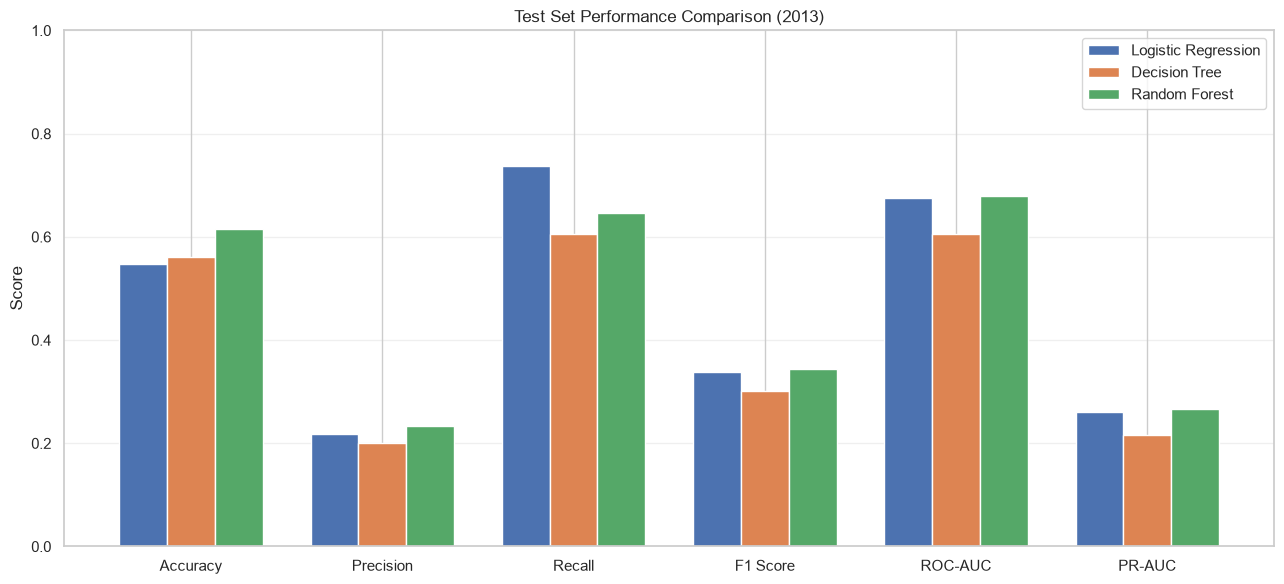

In [64]:
import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "Accuracy", "Precision", "Recall",
    "F1 Score", "ROC-AUC", "PR-AUC"
]

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(13, 6))

for i, row in test_results_df.iterrows():
    values = [row[metric] for metric in metrics]

    plt.bar(
        x + (i - 1) * width,
        values,
        width,
        label=row["Model"]
    )

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Test Set Performance Comparison (2013)")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"D:\Python Project\CrediScope\research\model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

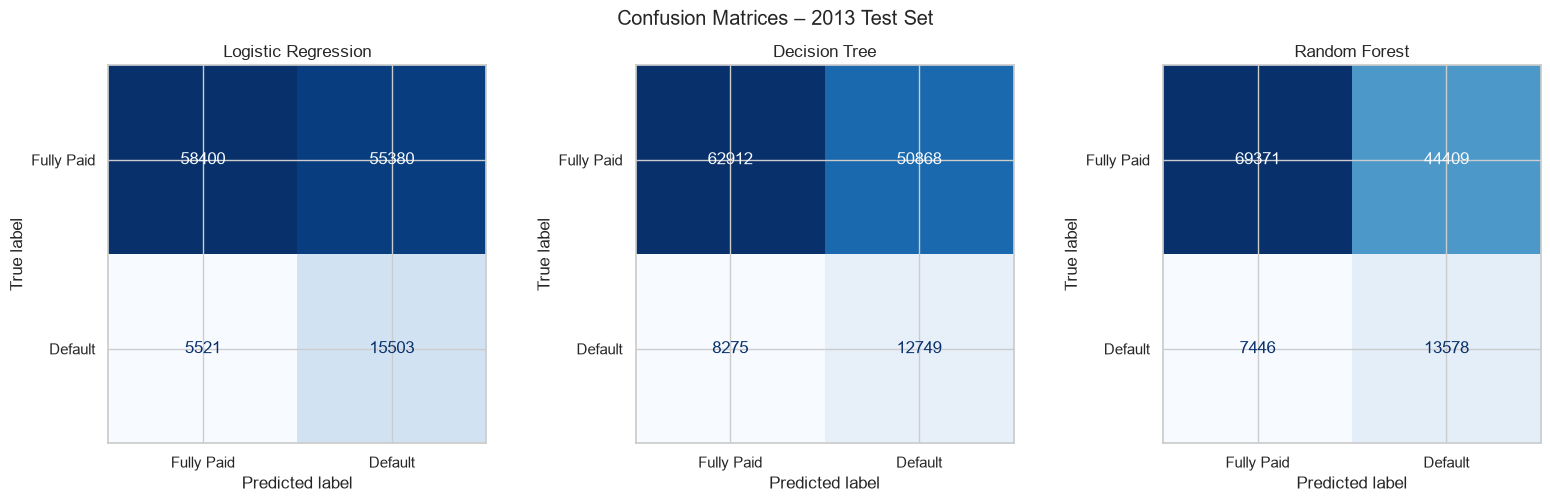

In [65]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, models.items()):

    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["Fully Paid", "Default"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrices – 2013 Test Set")
plt.tight_layout()

plt.savefig(
    r"D:\Python Project\CrediScope\research\confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

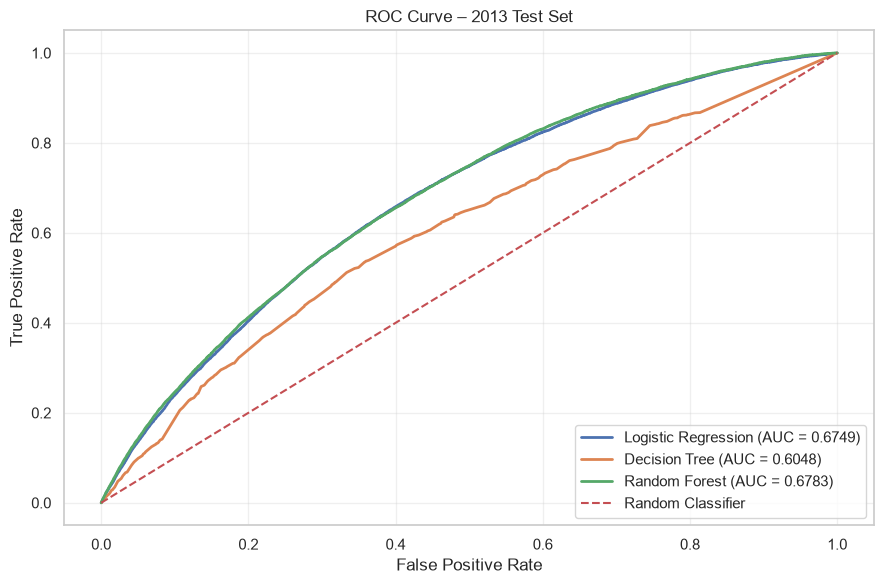

In [66]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(9, 6))

for name, model in models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – 2013 Test Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"D:\Python Project\CrediScope\research\roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

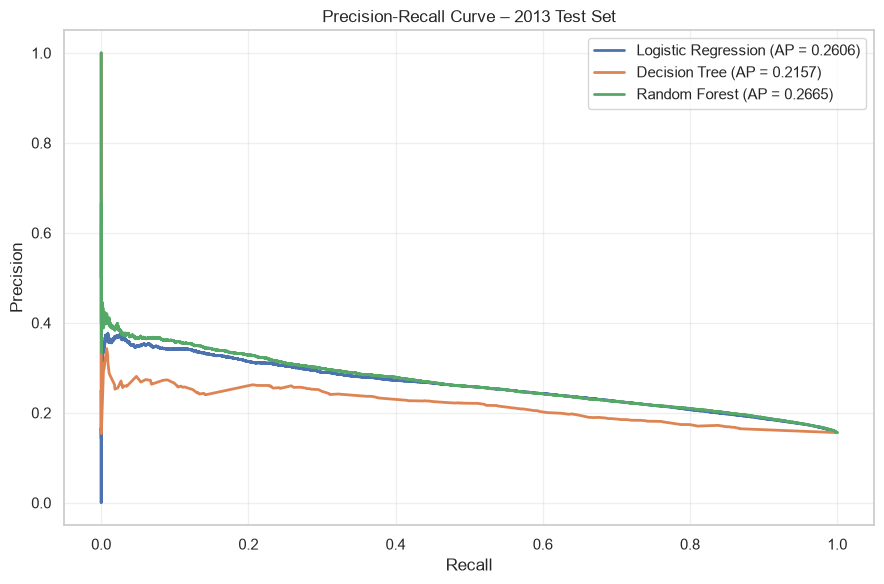

In [67]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(9, 6))

for name, model in models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        y_prob
    )

    pr_auc = average_precision_score(y_test, y_prob)

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP = {pr_auc:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve – 2013 Test Set")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    r"D:\Python Project\CrediScope\research\precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [68]:
# Extract feature importance from trained Random Forest

rf_model = models["Random Forest"]

rf_classifier = rf_model.named_steps["classifier"]
rf_preprocessor = rf_model.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
top_features = importance_df.head(15).copy()

top_features["Feature"] = (
    top_features["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

display(top_features)

,Feature,Importance
1,int_rate,0.145223
3,annual_inc,0.095509
9,revol_util,0.081555
4,dti,0.062621
8,revol_bal,0.061395
2,installment,0.060087
14,grade_A,0.059727
10,total_acc,0.048504
0,loan_amnt,0.047548
12,term_ 36 months,0.043436


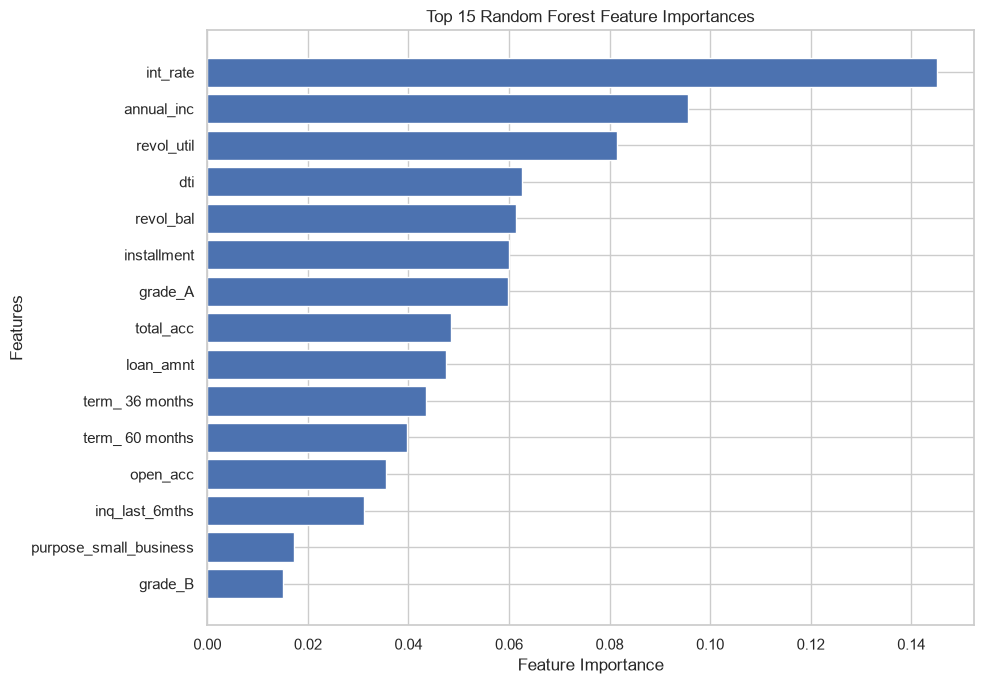

In [69]:
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Random Forest Feature Importances")

plt.tight_layout()

plt.savefig(
    r"D:\Python Project\CrediScope\research\feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [70]:
importance_df.to_csv(
    r"D:\Python Project\CrediScope\data\random_forest_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully.")

Feature importance saved successfully.


In [71]:
import joblib
import os

# Define model storage directory
model_dir = r"D:\Python Project\CrediScope\models"

os.makedirs(model_dir, exist_ok=True)

# Save all three trained pipelines
for name, model in models.items():

    filename = name.lower().replace(" ", "_") + ".joblib"

    save_path = os.path.join(model_dir, filename)

    joblib.dump(model, save_path)

    print(f"{name} saved successfully:")
    print(save_path)

# Save the primary Random Forest model separately
joblib.dump(
    models["Random Forest"],
    os.path.join(model_dir, "crediscope_primary_model.joblib")
)

print("\nAll trained models saved successfully.")

Logistic Regression saved successfully:
D:\Python Project\CrediScope\models\logistic_regression.joblib
Decision Tree saved successfully:
D:\Python Project\CrediScope\models\decision_tree.joblib
Random Forest saved successfully:
D:\Python Project\CrediScope\models\random_forest.joblib

All trained models saved successfully.
